# Pour commencer

Dans ce notebook, nous allons évaluer notre stratégie d'investissement.

Plan du notebook:
1. le chargement de la série temporelle
2. chargement de la stratégie
3. évaluation de la stratégie


La première chose à faire dans vos notebooks est donc de charger les classes de bases :


In [49]:
%run -i "BaseLoader.ipynb"
%run -i "BaseClasses.ipynb"
%run -i "BaseEvalGame.ipynb"

import os
from datetime import date

### Chargement de la série temporelle

In [72]:
loader = Loader(debug=True)

df = loader.get(Loader.GOOGLE_FINANCE, Loader.ETF_ISHARE_MSCI_CORE_MSCI_WORLD)

df.head()

init loader: . True
path ===== .\data\GoogleFinance\GoogleFinance-ETFisharesCoreMSCIWorld.csv  &  .
GoogleFinance [ ETFisharesCoreMSCIWorld ]  charged


,High,Low,Open,Close,Volume
Date,,,,,
2009-10-12,25.14,25.14,25.14,25.33,1075
2009-10-20,25.86,25.86,25.86,25.68,2000
2009-11-04,24.80,24.80,24.80,24.76,47872
2009-12-18,25.45,25.45,25.45,25.21,1675
2010-02-19,25.05,25.05,25.05,25.17,2700


In [73]:
df.tail()

,High,Low,Open,Close,Volume
Date,,,,,
2025-10-07,127.67,127.99,127.19,127.28,257133
2025-10-08,127.15,127.83,127.12,127.73,267121
2025-10-09,127.88,127.99,127.20,127.20,294336
2025-10-10,127.25,134.83,125.40,125.49,403958
2025-10-13,125.74,133.01,125.19,125.83,583347


Une sélection de l'intervalle de temps sur lequel faire le trading :

In [74]:
years = -1 # Dernières années, -1 pour tout prendre

if( years > 0 ):
    dfSliced = df.iloc[-252*10:]  # Dernières 10 années environ
else:
    dfSliced = df

dfSliced.head()

,High,Low,Open,Close,Volume
Date,,,,,
2009-10-12,25.14,25.14,25.14,25.33,1075
2009-10-20,25.86,25.86,25.86,25.68,2000
2009-11-04,24.80,24.80,24.80,24.76,47872
2009-12-18,25.45,25.45,25.45,25.21,1675
2010-02-19,25.05,25.05,25.05,25.17,2700


In [75]:
dfSliced.tail()

,High,Low,Open,Close,Volume
Date,,,,,
2025-10-07,127.67,127.99,127.19,127.28,257133
2025-10-08,127.15,127.83,127.12,127.73,267121
2025-10-09,127.88,127.99,127.20,127.20,294336
2025-10-10,127.25,134.83,125.40,125.49,403958
2025-10-13,125.74,133.01,125.19,125.83,583347


In [76]:
#dateStart = dfSliced.index[0]
dateStart = date(2015, 1, 2)  # For example, set a specific start date
# dateStart = date(2023, 1, 2)  # For example, set a specific start date
dateEnd = dfSliced.index[-1]

dfSliced = dfSliced.loc[dateStart:dateEnd]

print("Les dates de début et de fin sont:", dfSliced.index[0], "->", dfSliced.index[-1])

Les dates de début et de fin sont: 2015-01-02 00:00:00 -> 2025-10-13 00:00:00


C:\Users\antoi\AppData\Local\Temp\ipykernel_26716\3339763118.py:6: Pandas4Warning: Slicing with a datetime.date object is deprecated. Explicitly cast to Timestamp instead.
  dfSliced = dfSliced.loc[dateStart:dateEnd]


Puis nous sélectionnons la série temporelle que nous voulons utiliser.

<Axes: xlabel='Date'>

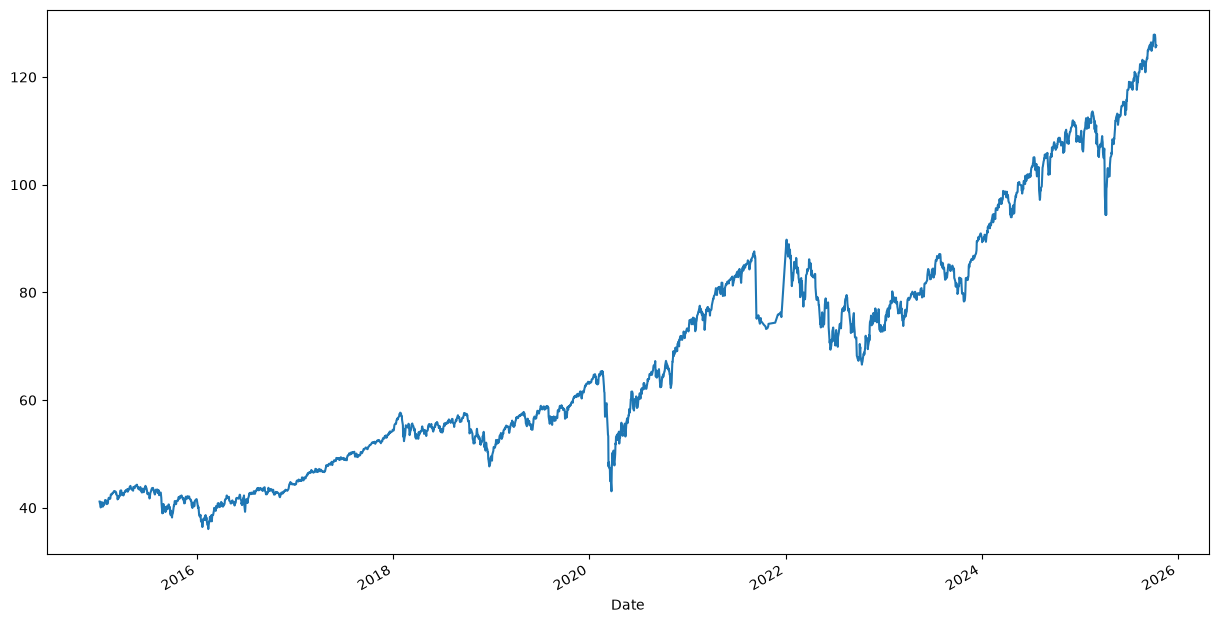

In [77]:
serie = dfSliced['Close']

plt.rcParams['figure.figsize'] = [15, 8] # paramètre pour les figures
serie.plot()

### Instanciation de la stratégie

La seconde chose à faire est d'instancier la stratégie, implémentée dans le fichier `Strategies.ipynb`.


In [78]:
%run -i "Strategies.ipynb"

In [79]:
strategy = StrategyInvest(amountInvest=1000)

print("La strategy chargée est:", strategy.name)


La strategy chargée est: StrategyInvest


### Évaluation de la stratégie / Chargement de la stratégie



In [80]:
evalGame = EvalGame(1000)

results = evalGame.evalTime(serie, data=None, strategy=strategy, debug=False)

EvalGame.saveResults(results, strategy.getName(), Loader.ETF_ISHARE_MSCI_CORE_MSCI_WORLD)

In [65]:
results = EvalGame.loadResults(strategy.name, Loader.ETF_ISHARE_MSCI_CORE_MSCI_WORLD)

In [81]:
gain = results.gain
cashInvest = results.cashInvest
tradingFees = results.tradingFees

In [82]:
tradingFees


Date
2015-01-02    258.7
2015-01-05    258.7
2015-01-06    258.7
2015-01-07    258.7
2015-01-08    258.7
              ...  
2025-10-07      0.0
2025-10-08      0.0
2025-10-09      0.0
2025-10-10      0.0
2025-10-13      0.0
Name: tradingFees, Length: 2667, dtype: float64

## Affichage des résultats

Nous pouvons maintenant afficher la courbe des prix, la courbe de gain de notre stratégie, la distribution de ces gains, et aussi quelques statistique sur la série, via la fonction `describe()` de Pandas.

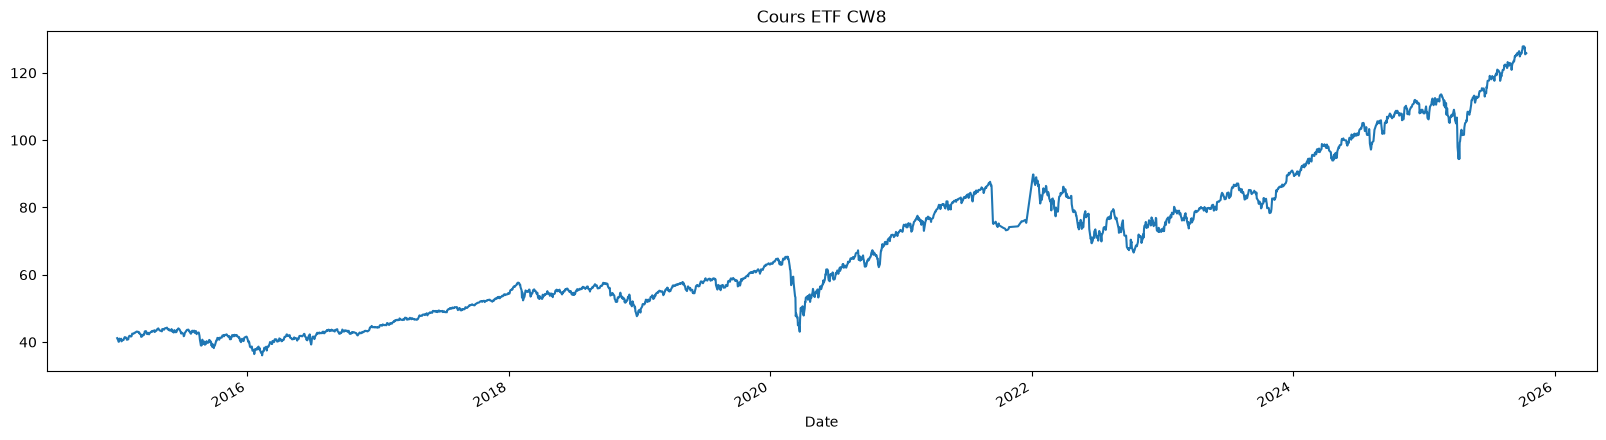

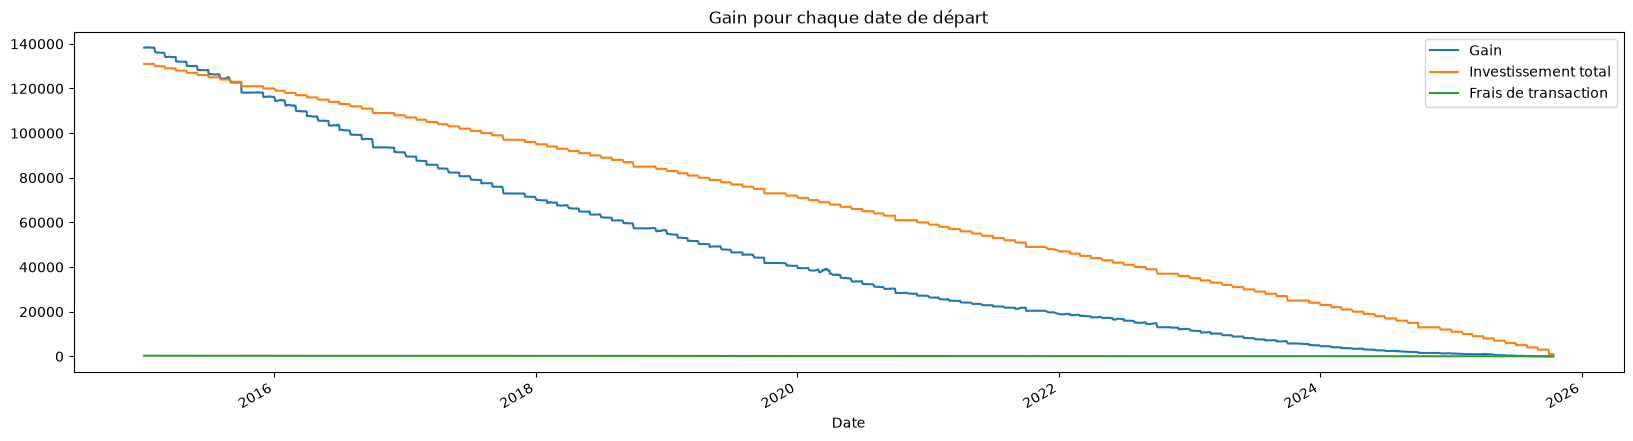

In [84]:
import seaborn as sns
plt.rcParams['figure.figsize'] = [15, 8] # paramètre pour les figures
dfSliced.Close.plot(figsize=(20,5), title="Cours ETF CW8")

# new figure
plt.figure()
# display gain and cashInvest with legends
gain.plot(figsize=(20,5), title="Gain pour chaque date de départ")
cashInvest.plot()
plt.legend(["Gain", "Investissement total"])
tradingFees.plot()
plt.legend(["Gain", "Investissement total", "Frais de transaction"])


## Distribution des gains

<Axes: ylabel='Frequency'>

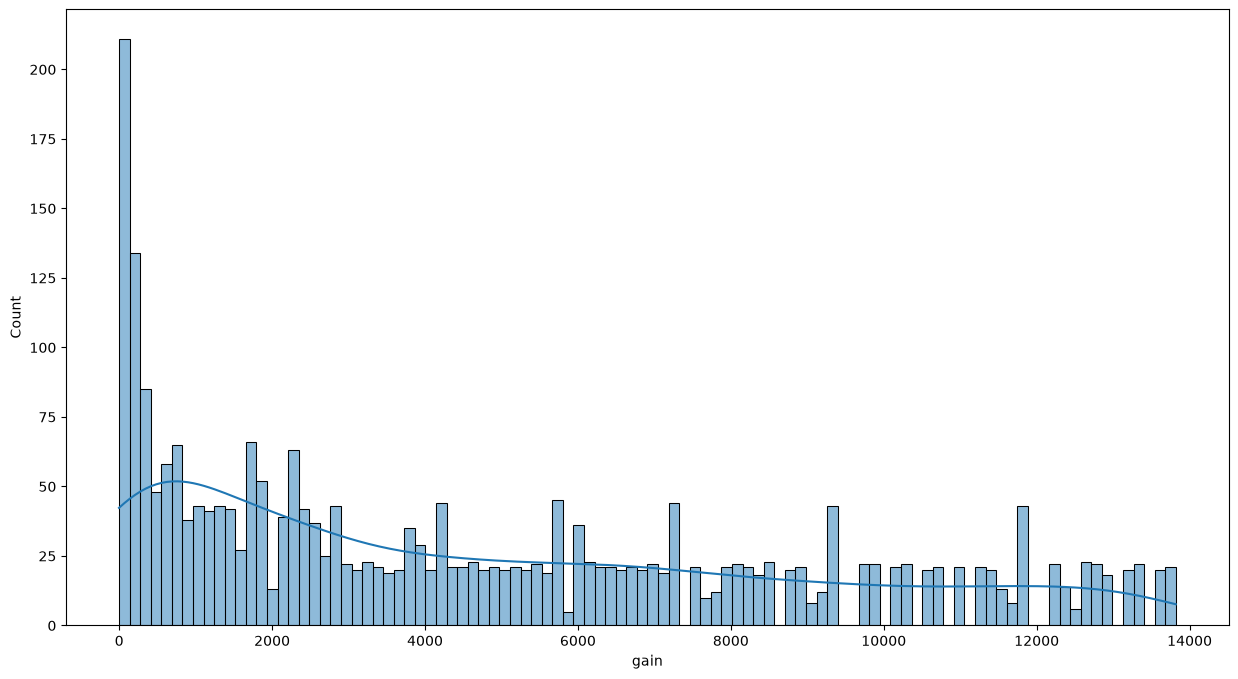

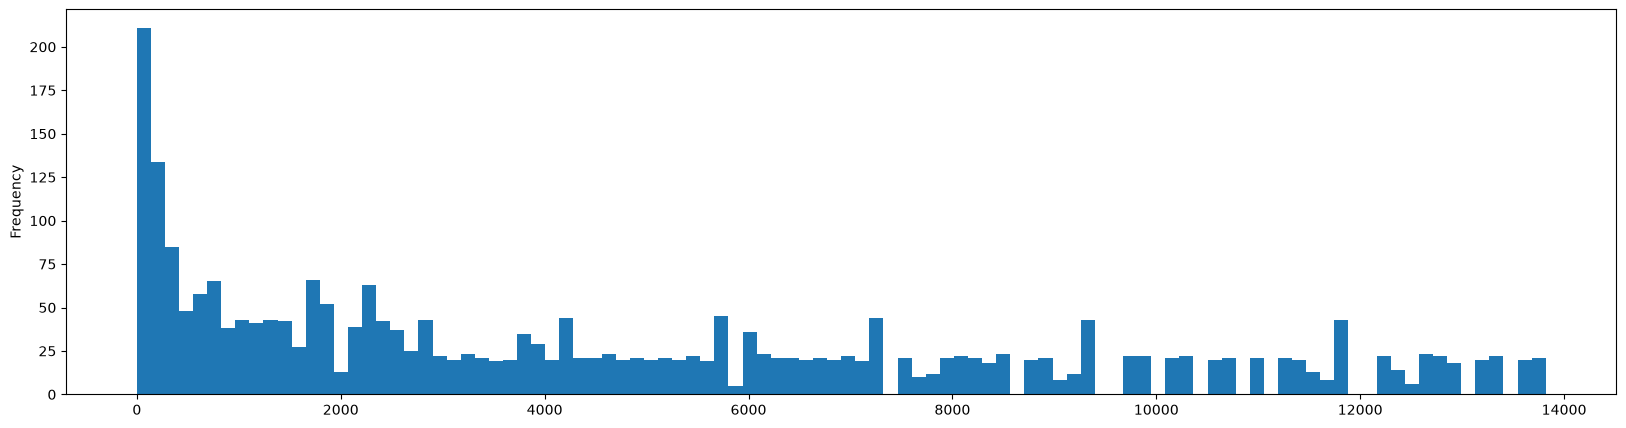

In [47]:

# new figure
plt.figure()
sns.histplot(gain, kde=True, bins=100)

# new figure
plt.figure()
gain.plot(kind='hist', bins=100, figsize=(20,5))

In [48]:
gain.describe()

count     2667.000000
mean      4703.312338
std       4093.979240
min         -2.348512
25%       1068.054613
50%       3655.062584
75%       7735.815765
max      13819.784658
Name: gain, dtype: float64

Calcul de la moyenne et de l'écart-type des gains journaliers.

In [ ]:
print(gain.mean())
print(gain.std())
print(gain.mean() / gain.std())

## Les valeurs mobilières VS ETF avec la stratégie d'investissement

Nous comparons ici la gains obtenus sur les valeurs mobilières du projet avec une stratégie d'investissement. 

Sur chaque valeur mobilière, votre objectif est donc double :
- vérifier que votre stratégie performe mieux que la stratégie investissement appliquée sur cette même valeur mobilière (sinon pourquoi s'embêter à faire plus compliqué que la stratégie investissement)
- vérifier que les gains obtenus avec votre stratégie sont meilleurs que ceux obtenus sur l'ETF

In [ ]:
serieNamesToTest = [Loader.BTC, Loader.AIRBUS, Loader.NVIDIA, Loader.STELLANTIS, Loader.TOTAL, Loader.CREDIT_AGRICOLE]
serieNamesCoins = [Loader.BTC]
serieNamesSecurity = [Loader. AIRBUS, Loader.NVIDIA, Loader.STELLANTIS, Loader.TOTAL, Loader.CREDIT_AGRICOLE]


serieNamesToTest

In [ ]:
# translate date to years-month-day string format

dateStrStart = dateStart.strftime('%Y-%m-%d')
dateStrEnd = dateEnd.strftime('%Y-%m-%d')

print("Date de début:", dateStrStart)
print("Date de fin:", dateStrEnd)

In [ ]:
seriesToTest = {}

for name in serieNamesToTest:
    if name in serieNamesCoins:
        seriesToTest[name] = loader.get(Loader.COINCODEX, name, dateStart=dateStrStart, dateEnd=dateStrEnd)
    elif name in serieNamesSecurity:
        seriesToTest[name] = loader.get(Loader.GOOGLE_FINANCE, name, dateStart=dateStrStart, dateEnd=dateStrEnd)
    print("Loaded coin:", name, " with [startDate, endDate]", seriesToTest[name].index[0], " -> " , seriesToTest[name].index[-1])

In [ ]:
seriesToTest[Loader.BTC].index[0]

In [ ]:

results = {}

for name, serie in seriesToTest.items():
    print("Évaluation de la série:", name)
    strategy = StrategyInvest()
    result = evalGame.evalTime(serie['Close'], data=None, strategy=strategy, debug=False)
    results[name] = result
    EvalGame.saveResults(result, strategy.getName(), name)

In [ ]:
results = {}

for name, serie in seriesToTest.items():
    print("Chargement des résultats de la série:", name)
    result = EvalGame.loadResults(strategy.name, name)
    results[name] = result

In [ ]:
# recupération de l'index des statistiques
btcDescribe = results[Loader.BTC].gain.describe()
index = btcDescribe.index

gainStd = "Gain/Std"
index = index.append(pd.Index([gainStd]))

allDescribes = pd.DataFrame(index=index)

for name, result in results.items():
    allDescribes[name] = result.gain.describe()
    allDescribes.loc[gainStd, name] = result.gain.mean() / result.gain.std()

allDescribes["ETF"] = gain.describe()
allDescribes.loc[gainStd, "ETF"] = gain.mean() / gain.std()

allDescribes

In [ ]:
plt.figure()
for name, result in results.items():
    plt.figure()
    result.gain.plot(figsize=(20,5), title="Gain pour chaque date de départ")
    gain.plot(figsize=(20,5), title="Gain pour chaque date de départ")
    plt.legend([name, "ETF"])

## Conclusion

Vous êtes maintenant prêt pour votre objectif final: implémenter une stratégie spéculative ayant un meilleur rendement que notre stratégie d'investissement.